# Entscheidungsbäume „from scratch“

Begleitnotebook zu **Vorlesung 9: Entscheidungsbäume**.

In diesem Notebook implementieren wir Entscheidungsbäume selbst – ohne fertige ML-Bibliothek, nur mit NumPy und pandas. So sehen wir, was hinter `sklearn.tree.DecisionTreeClassifier` und `DecisionTreeRegressor` steckt.

**Aufbau**

| Teil | Inhalt |
|---|---|
| 1 | Das Fahrrad-Beispiel aus der Vorlesung: Vorhersage, Entropie, Information Gain, Aufbau des Baums, Stoppkriterien |
| 2 | Komplexe Features: kategorische Features mit mehreren Ausprägungen, numerische Features, allgemeine Klasse |
| 3 | Größere Beispiele: Iris (Visualisierung, Feature Importance) und Titanic (Over- und Underfitting) |
| 4 | Regressionsbäume |

**Notation (wie auf den Folien)**

- $V$ = Label, $A_i$ = Ausprägung $i$ des Labels ($i = 1, \dots, k$)
- $W$ = Feature, $B_j$ = Ausprägung $j$ des Features ($j = 1, \dots, s$)
- $P(\dots)$ = relative Häufigkeit in den Trainingsdaten
- $H(V)$ = Entropie des Labels in einer Menge von Datenpunkten
- $H(V \mid W)$ = Entropie des Labels **nach** einem Split auf Feature $W$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

---
# Teil 1: Das Fahrrad-Beispiel

## 1.1 Daten

Wir nutzen den Datensatz aus der Vorlesung: An neun Tagen wurde notiert, ob ein Student **mit dem Fahrrad zur Hochschule** gefahren ist. Alle vier Features sind kategorisch und haben nur zwei Ausprägungen.

In [2]:
df = pd.DataFrame({
    "Wetter":      ["sonnig", "Regen", "Regen", "Regen", "sonnig", "Regen", "sonnig", "sonnig", "sonnig"],
    "Schnee":      ["nein", "nein", "nein", "nein", "nein", "nein", "nein", "ja", "ja"],
    "Auto kaputt": ["nein", "nein", "ja", "nein", "ja", "ja", "nein", "nein", "ja"],
    "Start 08:00": ["nein", "nein", "nein", "nein", "nein", "ja", "ja", "nein", "nein"],
    "Rad fahren":  ["ja", "nein", "ja", "nein", "ja", "ja", "nein", "nein", "nein"],
}, index=pd.RangeIndex(1, 10, name="Nr."))

X = df.drop(columns="Rad fahren")   # Features
y = df["Rad fahren"]                # Label
df

,Wetter,Schnee,Auto kaputt,Start 08:00,Rad fahren
Nr.,,,,,
1,sonnig,nein,nein,nein,ja
2,Regen,nein,nein,nein,nein
3,Regen,nein,ja,nein,ja
4,Regen,nein,nein,nein,nein
5,sonnig,nein,ja,nein,ja
6,Regen,nein,ja,ja,ja
7,sonnig,nein,nein,ja,nein
8,sonnig,ja,nein,nein,nein
9,sonnig,ja,ja,nein,nein


## 1.2 Vorhersage: den Baum traversieren

Bevor wir einen Baum **lernen**, schauen wir uns an, wie ein fertiger Baum eine **Vorhersage** macht.

Ein Baum besteht aus Knoten. An der Wurzel und an jedem inneren Knoten wird ein Feature evaluiert, je nach Ergebnis geht es im linken oder rechten Teilbaum weiter. In einem Blatt steht die Vorhersage.

Unsere Knoten prüfen immer eine Bedingung der Form „Feature = Wert“: Ist sie erfüllt, geht es nach **links**, sonst nach **rechts**.

In [3]:
class Node:
    # Ein Knoten des Baums: innerer Knoten (mit Split) oder Blatt (mit Vorhersage)

    def __init__(self, feature=None, value=None, left=None, right=None, prediction=None):
        self.feature = feature          # Feature, das an diesem Knoten evaluiert wird
        self.value = value              # Wert, mit dem das Feature verglichen wird
        self.left = left                # Teilbaum, wenn "Feature = Wert" erfüllt ist
        self.right = right              # Teilbaum, wenn nicht
        self.prediction = prediction    # Vorhersage (nur bei Blättern)

    def is_leaf(self):
        return self.left is None

Damit bauen wir den Baum, der in der Vorlesung am Ende des Trainings herauskommt, zunächst **von Hand** nach.

In [4]:
rad, nicht_rad = Node(prediction="ja"), Node(prediction="nein")

tree_slides = Node("Auto kaputt", "ja",
    left=Node("Schnee", "ja", left=nicht_rad, right=rad),
    right=Node("Wetter", "sonnig",
        left=Node("Schnee", "ja",
            left=nicht_rad,
            right=Node("Start 08:00", "ja", left=nicht_rad, right=rad)),
        right=nicht_rad))


def print_tree(node, indent=""):
    # Gibt den Baum eingerückt als verschachtelte Wenn-dann-Regeln aus
    if node.is_leaf():
        print(f"{indent}→ Vorhersage: {node.prediction}")
        return
    print(f"{indent}wenn {node.feature} = {node.value}:")
    print_tree(node.left, indent + "    ")
    print(f"{indent}sonst:")
    print_tree(node.right, indent + "    ")

print_tree(tree_slides)

wenn Auto kaputt = ja:
    wenn Schnee = ja:
        → Vorhersage: nein
    sonst:
        → Vorhersage: ja
sonst:
    wenn Wetter = sonnig:
        wenn Schnee = ja:
            → Vorhersage: nein
        sonst:
            wenn Start 08:00 = ja:
                → Vorhersage: nein
            sonst:
                → Vorhersage: ja
    sonst:
        → Vorhersage: nein


Die Vorhersage ist eine einfache Schleife: Wir starten an der Wurzel und laufen so lange nach links oder rechts, bis wir ein Blatt erreichen.

Zum Test nutzen wir die beiden Datenpunkte aus der Vorlesung.

In [5]:
def predict_one(node, x):
    # Traversiert den Baum für einen Datenpunkt x von der Wurzel bis zu einem Blatt
    while not node.is_leaf():
        node = node.left if x[node.feature] == node.value else node.right
    return node.prediction

tag_1 = {"Wetter": "sonnig", "Schnee": "ja",   "Start 08:00": "nein", "Auto kaputt": "nein"}
tag_2 = {"Wetter": "sonnig", "Schnee": "nein", "Start 08:00": "nein", "Auto kaputt": "nein"}

print("Tag 1 (Schnee):      Rad fahren =", predict_one(tree_slides, tag_1))
print("Tag 2 (kein Schnee): Rad fahren =", predict_one(tree_slides, tag_2))

Tag 1 (Schnee):      Rad fahren = nein
Tag 2 (kein Schnee): Rad fahren = ja


> **Zum Vergleich:** Bei der logistischen Regression setzen wir einen Datenpunkt in die Funktion $f(x)$ ein. Beim Entscheidungsbaum **traversieren** wir den Baum.

Das **Modelltraining** besteht jetzt darin, diese Baumstruktur aus den Trainingsdaten zu erzeugen. Dafür müssen wir entscheiden, welches Feature an welchem Knoten evaluiert wird.

## 1.3 Entropie

Jeder Knoten teilt die Trainingsdaten in zwei disjunkte Teilmengen – das ist ein **Split**. Ein Split ist gut, wenn das Label in den Teilmengen möglichst **homogen** ist.

Die „Unordnung“ in einer Menge messen wir mit der **Entropie**:

$$H(V) = -\sum_{i=1}^{k} P(A_i) \cdot \log_2 P(A_i)$$

Mit `np.unique` zählen wir, wie oft jede Ausprägung des Labels vorkommt. Ausprägungen, die gar nicht vorkommen, tauchen dabei nicht auf – der Fall $0 \cdot \log_2(0)$, den wir in der Vorlesung auf 0 setzen, tritt im Code also nie auf.

In [6]:
def entropy(labels):
    # Entropie H(V) einer Menge von Labels
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()                    # relative Häufigkeiten P(A_i)
    return float(-np.sum(p * np.log2(p))) + 0.0  # "+ 0.0" macht aus -0.0 eine 0.0

print("Nur 'ja':            ", entropy(["ja", "ja", "ja", "ja"]))
print("Halb 'ja', halb 'nein':", entropy(["ja", "ja", "nein", "nein"]))
print(f"Alle Trainingsdaten:   {entropy(y):.4f}   (4x ja, 5x nein)")

Nur 'ja':             0.0
Halb 'ja', halb 'nein': 1.0
Alle Trainingsdaten:   0.9911   (4x ja, 5x nein)


Bei zwei Klassen hängt die Entropie nur vom Anteil $p$ einer Klasse ab:

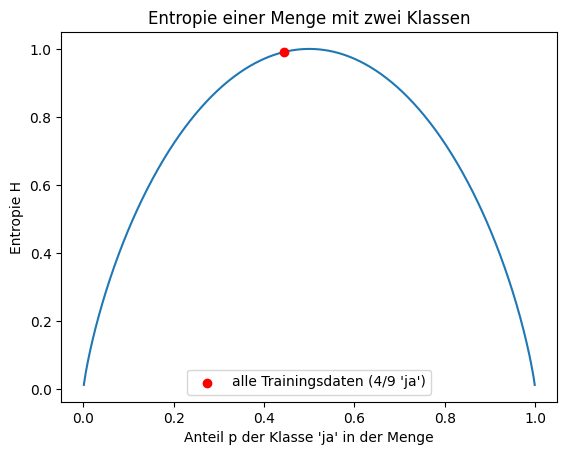

In [7]:
p = np.linspace(0.001, 0.999, 500)
H = -p * np.log2(p) - (1 - p) * np.log2(1 - p)

plt.plot(p, H)
plt.scatter([4 / 9], [entropy(y)], color="red", zorder=3, label="alle Trainingsdaten (4/9 'ja')")
plt.xlabel("Anteil p der Klasse 'ja' in der Menge")
plt.ylabel("Entropie H")
plt.legend(); plt.title("Entropie einer Menge mit zwei Klassen")
plt.show()

Die Entropie ist **0**, wenn alle Elemente gleich sind (perfekte Ordnung), und maximal **1**, wenn beide Klassen gleich häufig vorkommen. Unsere Trainingsdaten liegen mit 4× „ja“ und 5× „nein“ fast am Maximum.

## 1.4 Entropie nach einem Split

Ein Split zerlegt die Daten in Teilmengen. Die Entropie **nach** einem Split auf Feature $W$ ist der gewichtete Mittelwert der Entropien der Teilmengen:

$$H(V \mid W) = -\sum_{j=1}^{s} P(B_j) \sum_{i=1}^{k} P(A_i \mid B_j) \cdot \log_2 P(A_i \mid B_j) = \sum_{j=1}^{s} P(B_j) \cdot H(V \mid B_j)$$

Die innere Summe ist nichts anderes als die Entropie der Teilmenge, in der $W = B_j$ gilt. $P(B_j)$ ist der Anteil der Datenpunkte, die in dieser Teilmenge landen.

Wir rechnen das Beispiel aus der Vorlesung nach: **Split auf „Wetter“**.

In [8]:
sonnig = y[X["Wetter"] == "sonnig"]
regen = y[X["Wetter"] == "Regen"]

print(f"Wetter = sonnig: {len(sonnig)} von {len(y)} Datenpunkten, Labels: {list(sonnig)}")
print(f"                 Entropie = {entropy(sonnig):.4f}")
print(f"Wetter = Regen:  {len(regen)} von {len(y)} Datenpunkten, Labels: {list(regen)}")
print(f"                 Entropie = {entropy(regen):.4f}")

H_wetter = len(sonnig) / len(y) * entropy(sonnig) + len(regen) / len(y) * entropy(regen)
print(f"\nH(V | Wetter) = 5/9 · {entropy(sonnig):.4f} + 4/9 · {entropy(regen):.4f} = {H_wetter:.4f}")

Wetter = sonnig: 5 von 9 Datenpunkten, Labels: ['ja', 'ja', 'nein', 'nein', 'nein']
                 Entropie = 0.9710
Wetter = Regen:  4 von 9 Datenpunkten, Labels: ['nein', 'ja', 'nein', 'ja']
                 Entropie = 1.0000

H(V | Wetter) = 5/9 · 0.9710 + 4/9 · 1.0000 = 0.9839


Das ist der Wert von den Folien (dort nach der vierten Nachkommastelle abgeschnitten: 0.9838). Als Funktion, die für beliebige Features funktioniert:

In [9]:
def split_entropy(X, y, feature):
    # Entropie H(V | W) nach einem Split auf das Feature W
    h = 0.0
    for value in X[feature].unique():              # alle Ausprägungen B_j
        subset = y[X[feature] == value]            # Labels der Teilmenge mit W = B_j
        h += len(subset) / len(y) * entropy(subset)
    return h

tabelle = pd.DataFrame({"Entropie nach Split": {f: split_entropy(X, y, f) for f in X.columns}})
tabelle.round(4)

,Entropie nach Split
Wetter,0.9839
Schnee,0.7663
Auto kaputt,0.7616
Start 08:00,0.9885


**„Auto kaputt“** hat die geringste Entropie und wird für den ersten Split gewählt – knapp vor „Schnee“.

> **Achtung:** Nur der **gewichtete Mittelwert** wird durch einen Split nie größer als die Entropie der Ausgangsmenge. Eine **einzelne** Teilmenge kann durchaus unordentlicher sein: Die Regentage haben Entropie 1.0, alle Trainingsdaten zusammen nur 0.9911.

## 1.5 Information Gain

Der **Information Gain** gibt an, um wie viel ein Split die Entropie **reduziert**:

$$IG(V, W) = H(V) - H(V \mid W)$$

Weil $H(V)$ für alle Features gleich ist, ist „kleinste Entropie nach dem Split“ dasselbe wie „größter Information Gain“.

In [10]:
def information_gain(X, y, feature):
    return entropy(y) - split_entropy(X, y, feature)

tabelle["Information Gain"] = [information_gain(X, y, f) for f in X.columns]
tabelle.round(4)

,Entropie nach Split,Information Gain
Wetter,0.9839,0.0072
Schnee,0.7663,0.2248
Auto kaputt,0.7616,0.2294
Start 08:00,0.9885,0.0026


## 1.6 Den besten Split finden

An jedem Knoten probieren wir alle Features aus und nehmen das mit dem größten Information Gain.

Haben zwei Features **denselben** Information Gain, gewinnt bei uns das Feature, das in der Tabelle weiter links steht (`>` statt `>=`). Diese Regel ist willkürlich, muss aber festgelegt sein.

In [11]:
def best_split(X, y):
    # Liefert das Feature mit dem größten Information Gain
    best_feature, best_gain = None, 0.0
    for feature in X.columns:
        gain = information_gain(X, y, feature)
        if gain > best_gain + 1e-12:          # 1e-12 fängt Rundungsfehler ab
            best_feature, best_gain = feature, gain
    return best_feature, best_gain

print(best_split(X, y))

('Auto kaputt', 0.22943684069673975)


## 1.7 Den Baum aufbauen

Der Aufbau des Baums ist **rekursiv**:

1. Finde den besten Split für die aktuellen Daten.
2. Teile die Daten in zwei Teilmengen.
3. Wiederhole das Ganze für jede Teilmenge – so lange, bis ein **Stoppkriterium** greift. Dann wird ein Blatt erzeugt.

Im Blatt steht die Klasse, die in der Teilmenge am häufigsten vorkommt. Die Stoppkriterien aus der Vorlesung:

- Der Knoten ist **pure** (Entropie = 0).
- Kein Split reduziert die Entropie mehr.
- Die **maximale Baumtiefe** ist erreicht.

Für den Split nehmen wir die (alphabetisch) erste Ausprägung des gewählten Features als Vergleichswert: Datenpunkte mit „Feature = Wert“ gehen nach links, alle anderen nach rechts. Bei zwei Ausprägungen ist es egal, welche wir nehmen.

In [12]:
def build_tree(X, y, max_depth=None, depth=0, verbose=False):
    # Häufigste Klasse in dieser Teilmenge (wird zur Vorhersage, falls ein Blatt entsteht)
    classes, counts = np.unique(y, return_counts=True)
    majority = classes[np.argmax(counts)]
    indent = "    " * depth

    # Stoppkriterien 1 und 3: Knoten ist pure oder maximale Tiefe erreicht
    if entropy(y) == 0 or depth == max_depth:
        if verbose: print(f"{indent}Blatt mit Datenpunkten {list(y.index)} → {majority}")
        return Node(prediction=majority)

    # Stoppkriterium 2: kein Split reduziert die Entropie
    feature, gain = best_split(X, y)
    if feature is None:
        if verbose: print(f"{indent}Blatt mit Datenpunkten {list(y.index)} → {majority} (kein Split möglich)")
        return Node(prediction=majority)

    # Split durchführen und beide Teilbäume rekursiv aufbauen
    value = sorted(X[feature].unique())[0]
    mask = X[feature] == value
    if verbose: print(f"{indent}Split auf '{feature}' (Information Gain {gain:.4f}), Datenpunkte {list(y.index)}")

    return Node(feature, value,
                left=build_tree(X[mask], y[mask], max_depth, depth + 1, verbose),
                right=build_tree(X[~mask], y[~mask], max_depth, depth + 1, verbose))

tree = build_tree(X, y, verbose=True)

Split auf 'Auto kaputt' (Information Gain 0.2294), Datenpunkte [1, 2, 3, 4, 5, 6, 7, 8, 9]
    Split auf 'Schnee' (Information Gain 0.8113), Datenpunkte [3, 5, 6, 9]
        Blatt mit Datenpunkten [9] → nein
        Blatt mit Datenpunkten [3, 5, 6] → ja
    Split auf 'Wetter' (Information Gain 0.1710), Datenpunkte [1, 2, 4, 7, 8]
        Blatt mit Datenpunkten [2, 4] → nein
        Split auf 'Schnee' (Information Gain 0.2516), Datenpunkte [1, 7, 8]
            Blatt mit Datenpunkten [8] → nein
            Split auf 'Start 08:00' (Information Gain 1.0000), Datenpunkte [1, 7]
                Blatt mit Datenpunkten [7] → nein
                Blatt mit Datenpunkten [1] → ja


Die Ausgabe zeigt den Ablauf aus der Vorlesung: zuerst „Auto kaputt“, im linken Teilbaum (Datenpunkte 3, 5, 6, 9) trennt „Schnee“ perfekt, im rechten Teilbaum geht es mit „Wetter“ weiter.

Die Entropien der beiden Teilbäume können wir direkt mit den Folien vergleichen:

In [13]:
links = X["Auto kaputt"] == "ja"
kandidaten = ["Wetter", "Schnee", "Start 08:00"]

pd.DataFrame({
    "Auto kaputt = ja":   {f: split_entropy(X[links], y[links], f) for f in kandidaten},
    "Auto kaputt = nein": {f: split_entropy(X[~links], y[~links], f) for f in kandidaten},
}).round(4)

,Auto kaputt = ja,Auto kaputt = nein
Wetter,0.5000,0.551
Schnee,0.0000,0.649
Start 08:00,0.6887,0.649


Und der fertige Baum:

In [14]:
print_tree(tree)

wenn Auto kaputt = ja:
    wenn Schnee = ja:
        → Vorhersage: nein
    sonst:
        → Vorhersage: ja
sonst:
    wenn Wetter = Regen:
        → Vorhersage: nein
    sonst:
        wenn Schnee = ja:
            → Vorhersage: nein
        sonst:
            wenn Start 08:00 = ja:
                → Vorhersage: nein
            sonst:
                → Vorhersage: ja


Das ist derselbe Baum wie auf den Folien. Einziger Unterschied: Bei „Wetter“ steht bei uns „Regen“ links und „sonnig“ rechts – der Knoten ist gespiegelt, die Vorhersagen sind identisch.

> **Gleichstand:** Im Knoten mit den Datenpunkten 1, 7 und 8 haben „Schnee“ und „Start 08:00“ exakt denselben Information Gain. Unsere Regel wählt „Schnee“, weil es in der Tabelle weiter links steht. Mit „Start 08:00“ entstünde ein anderer, genauso guter Baum.

> **Muss man benutzte Features entfernen?** In der Vorlesung wird ein Feature nach dem Split aus der Kandidatenmenge entfernt. Im Code ist das nicht nötig: Nach dem Split auf „Auto kaputt“ haben alle Datenpunkte einer Teilmenge denselben Wert für dieses Feature. Ein weiterer Split darauf hätte Information Gain 0 und wird nie gewählt.

Zur Kontrolle: Der gelernte Baum klassifiziert alle Trainingsdaten richtig.

In [15]:
def predict(tree, X):
    return np.array([predict_one(tree, x) for x in X.to_dict("records")])

print("Vorhersagen:", predict(tree, X))
print("Labels:     ", y.to_numpy())
print("Anteil korrekt:", np.mean(predict(tree, X) == y.to_numpy()))

Vorhersagen: ['ja' 'nein' 'ja' 'nein' 'ja' 'ja' 'nein' 'nein' 'nein']
Labels:      ['ja' 'nein' 'ja' 'nein' 'ja' 'ja' 'nein' 'nein' 'nein']
Anteil korrekt: 1.0


## 1.8 Stoppkriterien

### Kein Split möglich

Nicht immer lassen sich alle Blätter pure machen. Haben zwei Datenpunkte **dieselben Features, aber verschiedene Labels**, kann kein Split sie trennen:

In [16]:
X_gleich = pd.DataFrame({"Wetter": ["sonnig", "sonnig"], "Schnee": ["nein", "nein"],
                         "Auto kaputt": ["nein", "nein"], "Start 08:00": ["nein", "nein"]})
y_gleich = pd.Series(["ja", "nein"])

print("Bester Split:", best_split(X_gleich, y_gleich))
print_tree(build_tree(X_gleich, y_gleich))

Bester Split: (None, 0.0)
→ Vorhersage: ja


Kein Feature reduziert die Entropie, also entsteht sofort ein Blatt. Bei Gleichstand der Klassen nimmt unsere Implementierung die alphabetisch erste.

### Maximale Baumtiefe

Die **Tiefe** eines Baums ist die Länge des längsten Pfads von der Wurzel zu einem Blatt. Die maximale Tiefe ist ein **Hyperparameter**, den wir vor dem Training festlegen.

Mit `max_depth=1` darf der Baum nur einmal splitten:

In [17]:
stump = build_tree(X, y, max_depth=1, verbose=True)
print()
print_tree(stump)

Split auf 'Auto kaputt' (Information Gain 0.2294), Datenpunkte [1, 2, 3, 4, 5, 6, 7, 8, 9]
    Blatt mit Datenpunkten [3, 5, 6, 9] → ja
    Blatt mit Datenpunkten [1, 2, 4, 7, 8] → nein

wenn Auto kaputt = ja:
    → Vorhersage: ja
sonst:
    → Vorhersage: nein


Die Blätter sind jetzt nicht mehr pure. Vorhergesagt wird die **häufigste Klasse** im Blatt.

Zusätzlich können wir eine **Vorhersagewahrscheinlichkeit** angeben: den Anteil der Klasse unter den Trainingsdatenpunkten im Blatt.

In [18]:
blatt_links = y[X["Auto kaputt"] == "ja"]
blatt_rechts = y[X["Auto kaputt"] == "nein"]

print("Blatt 'Auto kaputt = ja':  ", list(blatt_links), f"→ p('ja') = {np.mean(blatt_links == 'ja'):.2f}")
print("Blatt 'Auto kaputt = nein':", list(blatt_rechts), f"→ p('ja') = {np.mean(blatt_rechts == 'ja'):.2f}")

Blatt 'Auto kaputt = ja':   ['ja', 'ja', 'ja', 'nein'] → p('ja') = 0.75
Blatt 'Auto kaputt = nein': ['ja', 'nein', 'nein', 'nein', 'nein'] → p('ja') = 0.20


Im linken Blatt haben drei von vier Datenpunkten das Label „ja“ – die Vorhersage ist „Rad fahren“ mit Wahrscheinlichkeit 0.75.

---
# Teil 2: Komplexe Features

Bisher waren alle Features kategorisch mit genau zwei Ausprägungen. Jetzt verallgemeinern wir auf

- kategorische Features mit **mehr als zwei** Ausprägungen und
- **numerische** Features.

Als Beispiel nutzen wir den **Titanic-Datensatz**. Das Label `Survived` gibt an, ob eine Person den Untergang überlebt hat.

In [19]:
titanic = pd.read_csv("../data/titanic.csv")
titanic[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 2.1 Kategorische Features mit mehreren Ausprägungen

`Embarked` ist der Hafen, in dem eine Person zugestiegen ist: **S**outhampton, **C**herbourg oder **Q**ueenstown.

Unser Baum bleibt **binär**. Die Splits haben die Form „wenn Feature = Wert gehe links, sonst rechts“. Bei drei Ausprägungen gibt es also drei mögliche Splits, und für jeden berechnen wir die Entropie nach dem Split.

Dafür brauchen wir eine Funktion, die die Entropie für eine beliebige Aufteilung in „links“ und „rechts“ berechnet. `mask` gibt für jeden Datenpunkt an, ob er nach links geht.

In [20]:
def binary_split_entropy(y, mask):
    # Entropie nach einem binären Split: mask = True → links, mask = False → rechts
    n_left = np.sum(mask)
    return (n_left * entropy(y[mask]) + (len(y) - n_left) * entropy(y[~mask])) / len(y)

t = titanic.dropna(subset=["Embarked"])
y_t = t["Survived"].to_numpy()

print(f"Entropie vor dem Split: {entropy(y_t):.4f}\n")
for hafen in ["S", "C", "Q"]:
    mask = (t["Embarked"] == hafen).to_numpy()
    h = binary_split_entropy(y_t, mask)
    print(f"Embarked = {hafen} gegen Rest:  Entropie = {h:.4f},  Information Gain = {entropy(y_t) - h:.4f}")

Entropie vor dem Split: 0.9598

Embarked = S gegen Rest:  Entropie = 0.9434,  Information Gain = 0.0164
Embarked = C gegen Rest:  Entropie = 0.9394,  Information Gain = 0.0203
Embarked = Q gegen Rest:  Entropie = 0.9597,  Information Gain = 0.0000


Der beste Split auf diesem Feature wäre „Embarked = C gegen den Rest“.

## 2.2 Numerische Features

Bei numerischen Features haben Splits die Form „wenn Feature ≤ Schwelle gehe links, sonst rechts“. Die Frage ist: **Welche Schwellen** probieren wir aus?

**Variante 1 (Vorlesung): gleich große Intervalle.** Wir teilen den Bereich zwischen kleinstem und größtem Wert in $n$ gleich große Intervalle. Die Intervallgrenzen sind die **Split-Kandidaten**. Das Beispiel von den Folien: Temperaturen von −5 bis 25 Grad, $n = 6$.

In [21]:
def split_candidates_intervals(values, n):
    # n gleich große Intervalle zwischen min und max; die inneren Grenzen sind die Kandidaten
    return np.linspace(np.min(values), np.max(values), n + 1)[1:-1]

temperatur = np.array([-5, 12, 7, 25])
print("Split-Kandidaten:", split_candidates_intervals(temperatur, n=6))

Split-Kandidaten: [ 0.  5. 10. 15. 20.]


**Variante 2: alle vorkommenden Werte.** Gibt es nicht zu viele unterschiedliche Werte, können wir jede sinnvolle Schwelle prüfen. Zwischen zwei benachbarten Werten in den Trainingsdaten führt jede Schwelle zur selben Aufteilung – wir nehmen einfach die **Mitte**. So macht es auch sklearn.

In [22]:
def split_candidates_midpoints(values):
    # Mittelpunkte zwischen benachbarten, unterschiedlichen Werten
    u = np.unique(values)             # sortiert, ohne Duplikate
    return (u[:-1] + u[1:]) / 2

print("Werte:           ", np.unique(temperatur))
print("Split-Kandidaten:", split_candidates_midpoints(temperatur))

Werte:            [-5  7 12 25]
Split-Kandidaten: [ 1.   9.5 18.5]


Für jeden Kandidaten berechnen wir den Information Gain und nehmen den besten. Für das Feature `Age` im Titanic-Datensatz sieht das so aus:

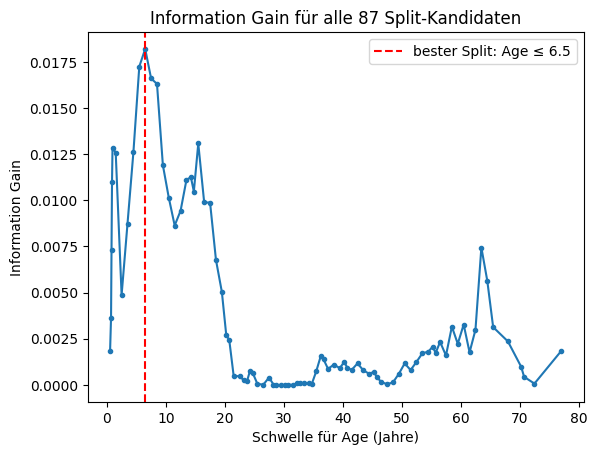

In [23]:
t = titanic.dropna(subset=["Age"])
alter, y_t = t["Age"].to_numpy(), t["Survived"].to_numpy()

kandidaten = split_candidates_midpoints(alter)
gains = np.array([entropy(y_t) - binary_split_entropy(y_t, alter <= k) for k in kandidaten])
best = np.argmax(gains)

plt.plot(kandidaten, gains, marker=".")
plt.axvline(kandidaten[best], color="red", ls="--", label=f"bester Split: Age ≤ {kandidaten[best]}")
plt.xlabel("Schwelle für Age (Jahre)")
plt.ylabel("Information Gain")
plt.legend(); plt.title(f"Information Gain für alle {len(kandidaten)} Split-Kandidaten")
plt.show()

Die beste Schwelle trennt **kleine Kinder** vom Rest – sie wurden bevorzugt gerettet.

> **Wichtig:** Anders als ein binäres Feature kann ein numerisches Feature im selben Pfad **mehrfach** vorkommen, jeweils mit einer anderen Schwelle (z. B. erst „Age ≤ 6.5“, weiter unten „Age ≤ 40“).

## 2.3 Eine allgemeine Klasse

Jetzt packen wir alles in eine Klasse, die wie sklearn-Modelle `fit` und `predict` anbietet. Neu gegenüber Teil 1:

- Jeder Knoten merkt sich, ob sein Split numerisch (`≤`) oder kategorisch (`=`) ist.
- Jeder Knoten speichert die Anzahl seiner Trainingsdatenpunkte, seine Entropie und die Klassenanteile (für die Vorhersagewahrscheinlichkeit).
- Als zusätzliches Stoppkriterium gibt es `min_samples_leaf`: Ein Split ist nur erlaubt, wenn in beiden Teilmengen mindestens so viele Datenpunkte landen.

Das Maß für die Unordnung (`_impurity`) und die Vorhersage im Blatt (`_leaf_value`) lagern wir in eigene Methoden aus. In Teil 4 müssen wir dann für Regressionsbäume nur diese beiden Methoden austauschen.

In [24]:
class Node:
    # Ein Knoten des Baums (erweitert gegenüber Teil 1)

    def __init__(self, n, impurity, prediction, proba=None):
        self.n = n                      # Anzahl Trainingsdatenpunkte in diesem Knoten
        self.impurity = impurity        # Unordnung (z. B. Entropie) in diesem Knoten
        self.prediction = prediction    # Vorhersage, falls dieser Knoten ein Blatt ist
        self.proba = proba              # Klassenanteile (nur Klassifizierung)
        self.feature = self.value = self.left = self.right = None
        self.numeric = False

    def is_leaf(self):
        return self.left is None

    def goes_left(self, x):
        # numerisch: "Feature ≤ Schwelle", kategorisch: "Feature = Wert"
        return x[self.feature] <= self.value if self.numeric else x[self.feature] == self.value

    def rule(self):
        return f"{self.feature} ≤ {self.value:.4g}" if self.numeric else f"{self.feature} = {self.value}"


class DecisionTreeScratch:
    # Gemeinsame Basis für Klassifizierungs- und Regressionsbäume

    def __init__(self, max_depth=None, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.features = list(X.columns)
        self.n_total = len(y)
        self.importance = dict.fromkeys(self.features, 0.0)   # für die Feature Importance (Teil 3)
        self.root = self._build(X.reset_index(drop=True), np.asarray(y), depth=0)
        return self

    def _candidates(self, column, numeric):
        if numeric:
            return split_candidates_midpoints(column)
        values = sorted(pd.unique(column))
        return values[:1] if len(values) == 2 else values     # bei 2 Ausprägungen reicht ein Kandidat

    def _best_split(self, X, y, parent_impurity):
        best = (None, None, None, 0.0, None)                  # Feature, Wert, numerisch?, Gain, Maske
        for feature in self.features:
            column = X[feature].to_numpy()
            numeric = pd.api.types.is_numeric_dtype(X[feature])
            for value in self._candidates(column, numeric):
                mask = column <= value if numeric else column == value
                n_left = np.sum(mask)
                if min(n_left, len(y) - n_left) < self.min_samples_leaf:
                    continue
                after = (n_left * self._impurity(y[mask]) + (len(y) - n_left) * self._impurity(y[~mask])) / len(y)
                gain = parent_impurity - after
                if gain > best[3] + 1e-12:
                    best = (feature, value, numeric, gain, mask)
        return best

    def _build(self, X, y, depth):
        node = self._make_node(y)

        # Stoppkriterien: Knoten ist pure oder maximale Tiefe erreicht
        if node.impurity < 1e-12 or depth == self.max_depth:
            return node

        # Stoppkriterium: kein Split reduziert die Unordnung
        feature, value, numeric, gain, mask = self._best_split(X, y, node.impurity)
        if feature is None:
            return node

        node.feature, node.value, node.numeric = feature, value, numeric
        self.importance[feature] += node.n / self.n_total * gain
        node.left = self._build(X[mask], y[mask], depth + 1)
        node.right = self._build(X[~mask], y[~mask], depth + 1)
        return node

    def _leaf(self, x):
        # Traversiert den Baum für einen Datenpunkt bis zum Blatt
        node = self.root
        while not node.is_leaf():
            node = node.left if node.goes_left(x) else node.right
        return node

    def predict(self, X):
        return np.array([self._leaf(x).prediction for x in X.to_dict("records")])

    def depth(self, node=None):
        node = node or self.root
        return 0 if node.is_leaf() else 1 + max(self.depth(node.left), self.depth(node.right))

    def n_leaves(self, node=None):
        node = node or self.root
        return 1 if node.is_leaf() else self.n_leaves(node.left) + self.n_leaves(node.right)

    def print(self, node=None, indent=""):
        node = node or self.root
        if node.is_leaf():
            pred = f"{node.prediction:.4g}" if isinstance(node.prediction, float) else node.prediction
            print(f"{indent}→ Vorhersage: {pred}  (n = {node.n})")
            return
        print(f"{indent}wenn {node.rule()}:")
        self.print(node.left, indent + "    ")
        print(f"{indent}sonst:")
        self.print(node.right, indent + "    ")


class DecisionTreeClassifierScratch(DecisionTreeScratch):
    # Entscheidungsbaum für Klassifizierung

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        return super().fit(X, y)

    def _impurity(self, y):
        return entropy(y)

    def _make_node(self, y):
        proba = np.array([np.mean(y == c) for c in self.classes_])   # Anteil jeder Klasse
        return Node(len(y), self._impurity(y), self.classes_[np.argmax(proba)], proba)

    def predict_proba(self, X):
        return np.array([self._leaf(x).proba for x in X.to_dict("records")])

## 2.4 Test mit dem Fahrrad-Beispiel

Die Klasse muss auf dem Fahrrad-Datensatz denselben Baum liefern wie unsere Funktion aus Teil 1.

In [25]:
model = DecisionTreeClassifierScratch().fit(X, y)
model.print()

print(f"\nTiefe: {model.depth()}, Blätter: {model.n_leaves()}")
print("Vorhersage für Tag 1 und Tag 2:", model.predict(pd.DataFrame([tag_1, tag_2])))

wenn Auto kaputt = ja:


    wenn Schnee = ja:
        → Vorhersage: nein  (n = 1)
    sonst:
        → Vorhersage: ja  (n = 3)
sonst:
    wenn Wetter = Regen:
        → Vorhersage: nein  (n = 2)
    sonst:
        wenn Schnee = ja:
            → Vorhersage: nein  (n = 1)
        sonst:
            wenn Start 08:00 = ja:
                → Vorhersage: nein  (n = 1)
            sonst:
                → Vorhersage: ja  (n = 1)

Tiefe: 4, Blätter: 6
Vorhersage für Tag 1 und Tag 2: ['nein' 'ja']


Und mit `max_depth=1` erhalten wir die Vorhersagewahrscheinlichkeiten aus Abschnitt 1.8. Die Spalten gehören zu den Klassen in `classes_`.

In [26]:
stump = DecisionTreeClassifierScratch(max_depth=1).fit(X, y)
proba = pd.DataFrame(stump.predict_proba(X), columns=[f"p('{c}')" for c in stump.classes_], index=X.index)
pd.concat([X[["Auto kaputt"]], proba, y], axis=1)

,Auto kaputt,p('ja'),p('nein'),Rad fahren
Nr.,,,,
1,nein,0.20,0.80,ja
2,nein,0.20,0.80,nein
3,ja,0.75,0.25,ja
4,nein,0.20,0.80,nein
5,ja,0.75,0.25,ja
6,ja,0.75,0.25,ja
7,nein,0.20,0.80,nein
8,nein,0.20,0.80,nein
9,ja,0.75,0.25,nein


---
# Teil 3: Größere Beispiele

## 3.1 Iris: numerische Features und Visualisierung

Der **Iris-Datensatz** enthält 150 Blüten von drei Schwertlilien-Arten. Wir nutzen zunächst nur zwei Features: Länge und Breite des Blütenblatts (*petal*). Wie im Beispiel aus der Vorlesung trainieren wir einen Baum mit maximaler Tiefe 2.

In [27]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
arten = iris.target_names                                 # ['setosa', 'versicolor', 'virginica']

X_iris = iris.data[["petal length (cm)", "petal width (cm)"]]
y_iris = arten[iris.target]                               # Label als Name der Art

iris_model = DecisionTreeClassifierScratch(max_depth=2).fit(X_iris, y_iris)
iris_model.print()

wenn petal length (cm) ≤ 2.45:
    → Vorhersage: setosa  (n = 50)
sonst:
    wenn petal width (cm) ≤ 1.75:
        → Vorhersage: versicolor  (n = 54)
    sonst:
        → Vorhersage: virginica  (n = 46)


Der erste Split trennt *setosa* perfekt ab, der zweite trennt *versicolor* und *virginica* weitgehend.

Zum Vergleich trainieren wir denselben Baum mit sklearn. Mit `criterion="entropy"` nutzt sklearn wie wir die Entropie.

In [28]:
from sklearn.tree import DecisionTreeClassifier, export_text

sk_iris = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=42).fit(X_iris, y_iris)
print(export_text(sk_iris, feature_names=list(X_iris.columns)))

print("Gleiche Vorhersagen wie unser Baum:", np.all(sk_iris.predict(X_iris) == iris_model.predict(X_iris)))

|--- petal length (cm) <= 2.45
|   |--- class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- class: versicolor
|   |--- petal width (cm) >  1.75
|   |   |--- class: virginica

Gleiche Vorhersagen wie unser Baum: True


Beide Bäume sind identisch: dieselben Features, dieselben Schwellen, dieselben Vorhersagen.

> **Gleichstand:** An der Wurzel trennen „petal length ≤ 2.45“ und „petal width ≤ 0.8“ die Art *setosa* beide perfekt ab und haben exakt denselben Information Gain. Wir nehmen das erste Feature in der Tabelle. sklearn entscheidet bei Gleichstand zufällig, gesteuert über `random_state` – mit einem anderen Wert kann dort „petal width“ an der Wurzel stehen.

### Decision Boundaries

Mit zwei Features lässt sich ein Entscheidungsbaum gut zeichnen. Jeder Split ist eine **achsenparallele Linie**, jedes Blatt ein **Rechteck**.

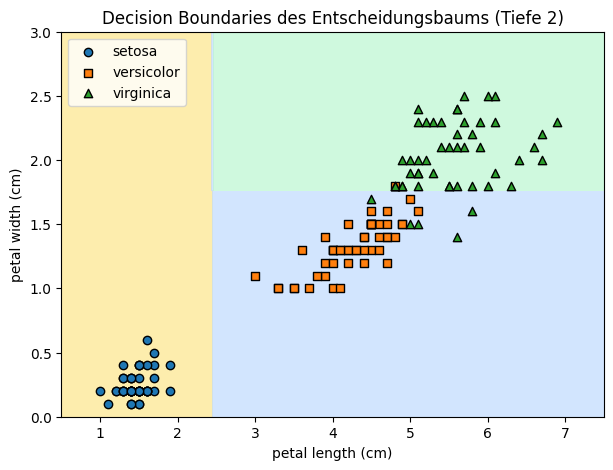

In [29]:
g1, g2 = np.meshgrid(np.linspace(0.5, 7.5, 200), np.linspace(0, 3, 200))
grid = pd.DataFrame({"petal length (cm)": g1.ravel(), "petal width (cm)": g2.ravel()})

pred = iris_model.predict(grid)
pred_nr = np.array([list(arten).index(p) for p in pred]).reshape(g1.shape)   # Art → 0, 1, 2

plt.figure(figsize=(7, 5))
plt.contourf(g1, g2, pred_nr, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#fde68a", "#bfdbfe", "#bbf7d0"], alpha=0.7)
for art, marker in zip(arten, ["o", "s", "^"]):
    m = y_iris == art
    plt.scatter(X_iris[m].iloc[:, 0], X_iris[m].iloc[:, 1], marker=marker, edgecolor="black", label=art)
plt.xlabel("petal length (cm)"); plt.ylabel("petal width (cm)")
plt.legend(loc="upper left"); plt.title("Decision Boundaries des Entscheidungsbaums (Tiefe 2)")
plt.show()

Anders als die logistische Regression (eine Gerade) setzt ein Baum seine Decision Boundary aus **achsenparallelen Stücken** zusammen. Mit genügend Tiefe kann er damit beliebig komplizierte Bereiche abgrenzen.

### Feature Importance

Als Faustregel gilt: Je näher ein Feature an der Wurzel steht, desto wichtiger ist es. Genauer lässt sich das berechnen, indem man für jedes Feature zusammenzählt, **wie stark seine Splits die Entropie reduziert haben** – gewichtet mit dem Anteil der Trainingsdaten, die am jeweiligen Knoten ankommen:

$$\text{Importance}(W) = \sum_{\text{Knoten } t \text{ mit Split auf } W} \frac{n_t}{n} \cdot IG_t$$

Am Ende werden die Werte so normiert, dass sie sich zu 1 summieren. Die Summe haben wir in `_build` schon mitgeführt (`self.importance`).

Jetzt trainieren wir mit allen vier Features:

In [30]:
def feature_importances(model):
    imp = pd.Series(model.importance)
    return imp / imp.sum()

X_iris4 = iris.data
iris_model4 = DecisionTreeClassifierScratch(max_depth=3).fit(X_iris4, y_iris)
sk_iris4 = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42).fit(X_iris4, y_iris)

pd.DataFrame({"unser Baum": feature_importances(iris_model4),
              "sklearn": sk_iris4.feature_importances_}).round(4)

,unser Baum,sklearn
sepal length (cm),0.0000,0.0000
sepal width (cm),0.0000,0.0000
petal length (cm),0.6898,0.6898
petal width (cm),0.3102,0.3102


Unsere Berechnung liefert dieselben Werte wie sklearn. „petal length“ ist das wichtigste Feature. Die beiden Kelchblatt-Features (*sepal*) kommen im Baum gar nicht vor und haben deshalb Importance 0.

## 3.2 Titanic: gemischte Features

Jetzt ein Datensatz mit numerischen **und** kategorischen Features. Unser Baum kann die Spalten `Sex` und `Embarked` direkt verarbeiten – ohne One-Hot-Encoding und ohne Feature-Scaling.

Fehlende Werte kann unsere Implementierung nicht verarbeiten. Wir füllen sie mit dem Median (`Age`) bzw. dem häufigsten Wert (`Embarked`) der **Trainingsdaten**.

In [31]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X_train, X_test, y_train, y_test = train_test_split(
    titanic[features], titanic["Survived"], test_size=0.2, random_state=42, stratify=titanic["Survived"])

fill = {"Age": X_train["Age"].median(), "Embarked": X_train["Embarked"].mode()[0]}
X_train, X_test = X_train.fillna(fill), X_test.fillna(fill)

print(f"Trainingsdaten: {len(y_train)} Punkte, Testdaten: {len(y_test)} Punkte")

titanic_model = DecisionTreeClassifierScratch(max_depth=3).fit(X_train, y_train)
titanic_model.print()

Trainingsdaten: 712 Punkte, Testdaten: 179 Punkte
wenn Sex = female:
    wenn Pclass ≤ 2.5:
        wenn Fare ≤ 28.86:
            → Vorhersage: 1  (n = 54)
        sonst:
            → Vorhersage: 1  (n = 83)
    sonst:
        wenn Fare ≤ 24.81:
            → Vorhersage: 1  (n = 98)
        sonst:
            → Vorhersage: 0  (n = 18)
sonst:
    wenn Age ≤ 3.5:
        wenn SibSp ≤ 2.5:
            → Vorhersage: 1  (n = 12)
        sonst:
            → Vorhersage: 0  (n = 3)
    sonst:
        wenn Pclass ≤ 1.5:
            → Vorhersage: 0  (n = 91)
        sonst:
            → Vorhersage: 0  (n = 353)


Der Baum ist direkt lesbar: Zuerst wird nach dem **Geschlecht** getrennt, danach spielen Klasse, Alter und Ticketpreis eine Rolle. Diese Interpretierbarkeit ist eine große Stärke von Entscheidungsbäumen.

Accuracy auf Trainingsdaten: 0.826
Accuracy auf Testdaten:      0.804


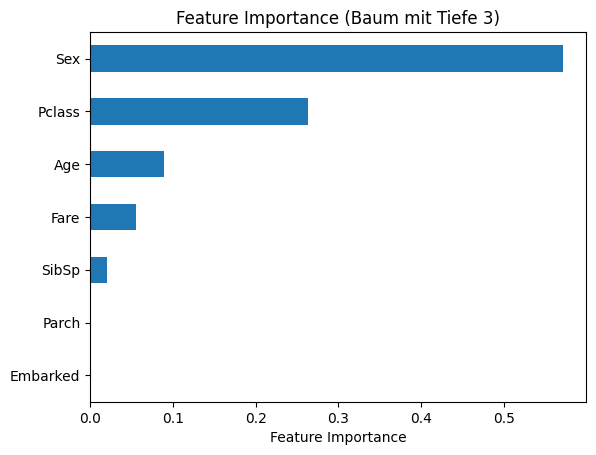

In [32]:
def accuracy(model, X, y):
    return np.mean(model.predict(X) == np.asarray(y))

print(f"Accuracy auf Trainingsdaten: {accuracy(titanic_model, X_train, y_train):.3f}")
print(f"Accuracy auf Testdaten:      {accuracy(titanic_model, X_test, y_test):.3f}")

feature_importances(titanic_model).sort_values().plot.barh()
plt.xlabel("Feature Importance"); plt.title("Feature Importance (Baum mit Tiefe 3)")
plt.show()

## 3.3 Over- und Underfitting

Was passiert, wenn wir die maximale Tiefe verändern? Wir trainieren Bäume mit Tiefe 1 bis 15 und einen Baum ganz ohne Begrenzung.

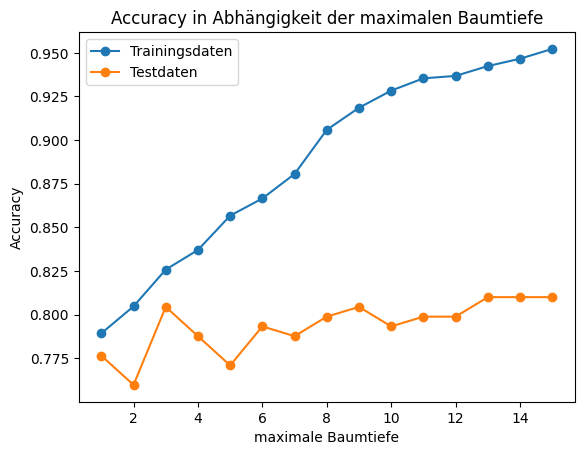

Baum ohne Begrenzung: Tiefe 22, 153 Blätter bei 712 Trainingsdatenpunkten
Accuracy auf Trainingsdaten: 0.983
Accuracy auf Testdaten:      0.810


In [33]:
depths = list(range(1, 16))
train_acc, test_acc, leaves = [], [], []

for d in depths:
    m = DecisionTreeClassifierScratch(max_depth=d).fit(X_train, y_train)
    train_acc.append(accuracy(m, X_train, y_train))
    test_acc.append(accuracy(m, X_test, y_test))
    leaves.append(m.n_leaves())

plt.plot(depths, train_acc, marker="o", label="Trainingsdaten")
plt.plot(depths, test_acc, marker="o", label="Testdaten")
plt.xlabel("maximale Baumtiefe"); plt.ylabel("Accuracy")
plt.legend(); plt.title("Accuracy in Abhängigkeit der maximalen Baumtiefe")
plt.show()

full = DecisionTreeClassifierScratch().fit(X_train, y_train)
print(f"Baum ohne Begrenzung: Tiefe {full.depth()}, {full.n_leaves()} Blätter bei {len(y_train)} Trainingsdatenpunkten")
print(f"Accuracy auf Trainingsdaten: {accuracy(full, X_train, y_train):.3f}")
print(f"Accuracy auf Testdaten:      {accuracy(full, X_test, y_test):.3f}")

- Die Accuracy auf den **Trainingsdaten** steigt mit jeder zusätzlichen Ebene. Ohne Begrenzung erreicht der Baum über 98 % – er hat die Trainingsdaten praktisch auswendig gelernt. (100 % sind nicht möglich, weil es Personen mit identischen Features, aber unterschiedlichem Label gibt, siehe Abschnitt 1.8.)
- Die Accuracy auf den **Testdaten** profitiert davon nicht. Sie schwankt ab Tiefe 3 um 80 %, egal wie groß der Baum wird.

Der Abstand zwischen beiden Kurven wird immer größer: Das ist **Overfitting**. Ein Baum mit 8 Blättern (Tiefe 3) sagt auf neuen Daten praktisch genauso gut vorher wie ein Baum mit über 150 Blättern – und ist dabei noch lesbar.

> Bei 179 Testdatenpunkten entspricht ein einzelner Datenpunkt 0.6 Prozentpunkten. Das Auf und Ab der Testkurve ist deshalb größtenteils Zufall. Um die beste Tiefe verlässlich zu bestimmen, nutzt man in der Praxis **Cross-Validation**.

## 3.4 Vergleich mit sklearn

`sklearn.tree.DecisionTreeClassifier` unterscheidet sich in zwei Punkten von unserer Implementierung:

- **Kategorische Features** kann sklearn nicht direkt verarbeiten, sie müssen vorher in Zahlen umgewandelt werden. Wir nutzen One-Hot-Encoding. Ein Split „Sex_male ≤ 0.5“ ist dann genau unser Split „Sex = female“.
- Als Maß für die Unordnung nutzt sklearn standardmäßig nicht die Entropie, sondern die **Gini Impurity** $G = 1 - \sum_i P(A_i)^2$. Sie verhält sich sehr ähnlich, kommt aber ohne Logarithmus aus. Mit `criterion="entropy"` rechnet sklearn wie wir.

In [34]:
X_train_oh = pd.get_dummies(X_train)                                             # One-Hot-Encoding
X_test_oh = pd.get_dummies(X_test).reindex(columns=X_train_oh.columns, fill_value=0)

rows = []
for d in [1, 2, 3, 5, 8]:
    ours = DecisionTreeClassifierScratch(max_depth=d).fit(X_train, y_train)
    sk = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42).fit(X_train_oh, y_train)
    rows.append({"max. Tiefe": d,
                 "Blätter (wir)": ours.n_leaves(), "Blätter (sklearn)": sk.get_n_leaves(),
                 "Train (wir)": accuracy(ours, X_train, y_train), "Train (sklearn)": sk.score(X_train_oh, y_train),
                 "Test (wir)": accuracy(ours, X_test, y_test), "Test (sklearn)": sk.score(X_test_oh, y_test)})
pd.DataFrame(rows).set_index("max. Tiefe").round(3)

,Blätter (wir),Blätter (sklearn),Train (wir),Train (sklearn),Test (wir),Test (sklearn)
max. Tiefe,,,,,,
1,2,2,0.789,0.789,0.777,0.777
2,4,4,0.805,0.805,0.760,0.760
3,8,8,0.826,0.826,0.804,0.804
5,22,22,0.857,0.857,0.771,0.771
8,52,52,0.906,0.906,0.799,0.793


Anzahl der Blätter und Accuracy auf den Trainingsdaten stimmen für jede Tiefe überein. Das zeigt auch: Ein Split auf einer One-Hot-Spalte ist gleichwertig zu unserem Split „Feature = Wert“.

Kleine Abweichungen auf den Testdaten bei tiefen Bäumen entstehen durch **Gleichstände**: Haben zwei Splits denselben Information Gain, wählen wir und sklearn nicht immer denselben. Beide Bäume sind auf den Trainingsdaten gleich gut, verhalten sich auf neuen Daten aber leicht unterschiedlich.

---
# Teil 4: Regressionsbäume

Entscheidungsbäume funktionieren auch für **Regression**. Es ändern sich nur zwei Dinge:

- Die **Vorhersage** in einem Blatt ist der **Durchschnitt** der Labels aller Trainingsdatenpunkte im Blatt.
- Die Güte eines Splits messen wir nicht mit der Entropie, sondern mit dem **MSE** nach dem Split.

## 4.1 Das Beispiel aus der Vorlesung

Drei Datenpunkte, zwei mögliche Splits auf dem TV-Budget:

In [35]:
werbung = pd.DataFrame({"TV-Budget": [50, 100, 300], "Radio-Budget": [10, 20, 100], "Umsatz": [9, 12, 17]})

def mse_after_split(y, mask):
    # Vorhersage = Mittelwert der jeweiligen Teilmenge, dann MSE über alle Datenpunkte
    pred = np.where(mask, y[mask].mean(), y[~mask].mean())
    return pred, np.mean((pred - y) ** 2)

umsatz = werbung["Umsatz"].to_numpy()
for schwelle in [50, 100]:
    pred, mse = mse_after_split(umsatz, (werbung["TV-Budget"] <= schwelle).to_numpy())
    print(f"TV-Budget ≤ {schwelle:>3}:  Vorhersagen = {pred},  MSE = {mse:.2f}")

TV-Budget ≤  50:  Vorhersagen = [ 9.  14.5 14.5],  MSE = 4.17
TV-Budget ≤ 100:  Vorhersagen = [10.5 10.5 17. ],  MSE = 1.50


Der Split „TV-Budget ≤ 100“ hat den kleineren MSE und wird gewählt.

## 4.2 Regressionsbaum als Klasse

Der MSE nach einem Split ist der gewichtete Mittelwert der **Varianzen** der beiden Teilmengen – denn die Varianz ist genau der mittlere quadratische Abstand zum Mittelwert. Die Varianz spielt hier also dieselbe Rolle wie die Entropie bei der Klassifizierung.

Wir müssen in unserer Klasse deshalb nur die beiden Methoden `_impurity` und `_make_node` austauschen. Der gesamte Rest (Split-Kandidaten, rekursiver Aufbau, Stoppkriterien, Traversieren) bleibt gleich.

In [36]:
class DecisionTreeRegressorScratch(DecisionTreeScratch):
    # Entscheidungsbaum für Regression

    def _impurity(self, y):
        return np.var(y)                              # MSE bezogen auf den Mittelwert

    def _make_node(self, y):
        return Node(len(y), self._impurity(y), np.mean(y))   # Vorhersage = Durchschnitt

reg_bsp = DecisionTreeRegressorScratch(max_depth=1).fit(werbung[["TV-Budget", "Radio-Budget"]], werbung["Umsatz"])
reg_bsp.print()

wenn TV-Budget ≤ 200:
    → Vorhersage: 10.5  (n = 2)
sonst:
    → Vorhersage: 17  (n = 1)


Der Baum wählt denselben Split wie die Rechnung von Hand. Als Schwelle steht die Mitte zwischen 100 und 300 – die Aufteilung der Datenpunkte ist dieselbe wie bei „TV-Budget ≤ 100“.

## 4.3 Ein Feature: Wie sieht die Vorhersagefunktion aus?

Wir nutzen den **Advertising-Datensatz** aus der Vorlesung zur linearen Regression und sagen zunächst den Umsatz (`sales`) nur aus dem TV-Budget vorher.

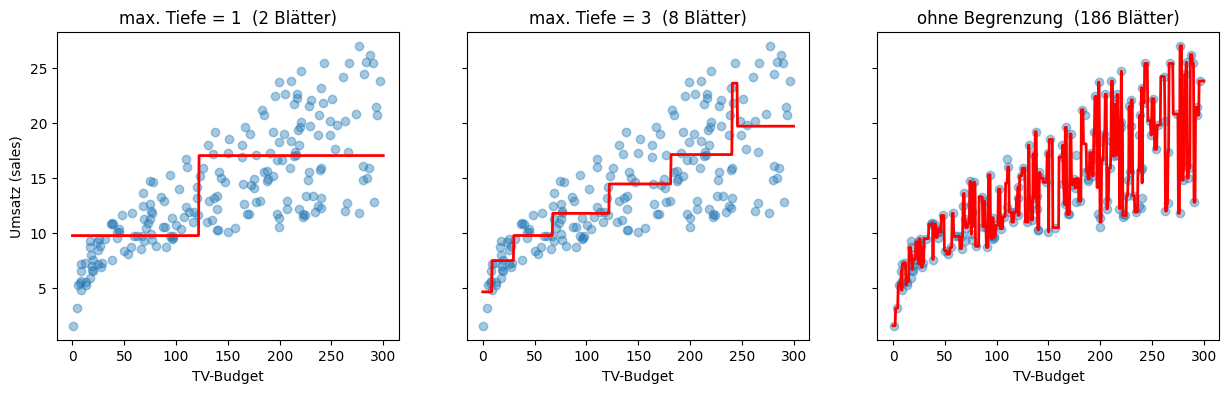

In [37]:
adv = pd.read_csv("../data/advertising.csv")
X_tv, y_sales = adv[["TV"]], adv["sales"]

tv_line = pd.DataFrame({"TV": np.linspace(0, 300, 600)})

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d in zip(axes, [1, 3, None]):
    m = DecisionTreeRegressorScratch(max_depth=d).fit(X_tv, y_sales)
    ax.scatter(adv["TV"], adv["sales"], alpha=0.4)
    ax.plot(tv_line["TV"], m.predict(tv_line), color="red", lw=2)
    ax.set_title(f"max. Tiefe = {d}  ({m.n_leaves()} Blätter)" if d else f"ohne Begrenzung  ({m.n_leaves()} Blätter)")
    ax.set_xlabel("TV-Budget")
axes[0].set_ylabel("Umsatz (sales)")
plt.show()

Ein Regressionsbaum lernt eine **Treppenfunktion**: Jedes Blatt entspricht einer Stufe, deren Höhe der Durchschnitt der Datenpunkte im Blatt ist.

- Mit Tiefe 1 gibt es nur zwei Stufen – das Modell ist zu einfach (**Underfitting**).
- Ohne Begrenzung bekommt praktisch jeder Datenpunkt seine eigene Stufe – das Modell lernt die Trainingsdaten auswendig (**Overfitting**).

> **Achtung:** Ein Baum kann nicht **extrapolieren**. Für ein TV-Budget, das größer ist als alle Werte in den Trainingsdaten, sagt er einfach den Wert der letzten Stufe vorher.

## 4.4 Alle Features und Vergleich mit sklearn

In [38]:
from sklearn.tree import DecisionTreeRegressor

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    adv[["TV", "radio", "newspaper"]], adv["sales"], test_size=0.2, random_state=42)

def mse(model, X, y):
    return np.mean((model.predict(X) - np.asarray(y)) ** 2)

rows = []
for d in [1, 2, 3, 5, 8, None]:
    ours = DecisionTreeRegressorScratch(max_depth=d).fit(Xa_train, ya_train)
    sk = DecisionTreeRegressor(max_depth=d, random_state=42).fit(Xa_train, ya_train)
    rows.append({"max. Tiefe": d if d else "ohne",
                 "Train-MSE (wir)": mse(ours, Xa_train, ya_train), "Train-MSE (sklearn)": mse(sk, Xa_train, ya_train),
                 "Test-MSE (wir)": mse(ours, Xa_test, ya_test), "Test-MSE (sklearn)": mse(sk, Xa_test, ya_test)})
pd.DataFrame(rows).set_index("max. Tiefe").round(3)

,Train-MSE (wir),Train-MSE (sklearn),Test-MSE (wir),Test-MSE (sklearn)
max. Tiefe,,,,
1,14.213,14.213,14.770,14.770
2,5.680,5.680,3.896,3.896
3,2.690,2.690,4.957,4.957
5,0.386,0.386,2.121,2.697
8,0.018,0.018,1.672,2.242
ohne,0.000,0.000,1.656,2.175


Auf den Trainingsdaten sind beide Implementierungen identisch. Bei tiefen Bäumen weichen die Werte auf den Testdaten voneinander ab – wieder wegen Gleichständen: In einem Knoten mit zwei Datenpunkten trennt zum Beispiel jedes Feature die beiden gleich gut, die Wahl ist beliebig.

Ohne Begrenzung ist der MSE auf den Trainingsdaten exakt 0: Jeder Datenpunkt sitzt in seinem eigenen Blatt.

---
# Zusammenfassung

- Ein Entscheidungsbaum macht Vorhersagen, indem er für einen Datenpunkt von der Wurzel bis zu einem Blatt **traversiert** wird.
- Beim **Training** wird der Baum rekursiv aufgebaut: An jedem Knoten wird der Split mit dem größten **Information Gain** gewählt (Klassifizierung) bzw. dem kleinsten **MSE** (Regression).
- Das Verfahren ist **greedy**: Es wählt an jedem Knoten den lokal besten Split und nimmt ihn nie zurück. Der entstehende Baum ist gut, aber nicht garantiert der bestmögliche.
- Bäume brauchen **kein Feature-Scaling** und können im Prinzip direkt mit kategorischen Features umgehen.
- Ohne Begrenzung der Tiefe lernen Bäume die Trainingsdaten auswendig (**Overfitting**). Die maximale Baumtiefe ist deshalb ein wichtiger Hyperparameter.

In der nächsten Vorlesung kombinieren wir viele Bäume zu **Ensembles** (Random Forest, Gradient Boosting) – und bekommen damit deutlich bessere Modelle.